# 05 – Regression Analysis (W10): dự báo giá trị mua 90 ngày
**Câu hỏi:** tại mỗi cutoff, khách hàng đã từng mua sẽ mua bao nhiêu GBP trong 90 ngày tới? Target là tổng tiền sản phẩm hợp lệ của đơn bắt đầu trong `[cutoff, cutoff+90 ngày)`, chỉ cộng dòng trong cửa sổ; không trừ hoàn trả, không tính tiếp nối hóa đơn cũ, zero nếu không có đơn mới. Không phải doanh thu ròng hoặc CLV trọn đời. Cùng logic W11, không dùng profile toàn kỳ. Khách có thể lặp lại ở các snapshot; không dự báo cold-start.

**Protocol cố định:** 01/03, 01/06, 01/09/2011 (train/validation/test); labels không chồng lấn. 7 feature số định trước từ W11, không dùng ID/nhãn/địa lý; tránh đồng thời frequency, AOV và gross = frequency × AOV. Impute/log1p/scale fit trong từng fold train. So sánh hai dummy (median cho MAE, mean cho RMSE), OLS, Ridge và Lasso. 5-fold CV trong snapshot train chọn MAE thấp nhất (hòa: RMSE rồi tên), chọn alpha từng họ trước khi nhìn validation/test. Các mô hình fit train, giữ nguyên qua validation và test, không refit/tune theo test. Clip dự báo âm về 0 ở tất cả bước đánh giá; OLS diagnostics dùng dự báo tuyến tính chưa clip. W10 slide 32 (workflow), LINE, VIF, Cook, HC3. Mọi kết quả trong notebook chỉ từ dữ liệu chạy thực tế.

In [1]:
from pathlib import Path
import sys
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p/'src'/'regression_evaluation.py').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Mở notebook từ repository.')
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from src.pipeline import run_pipeline
from src.regression_evaluation import (CUTOFFS, TARGET, FEATURES, REG_FEATURES, regression_datasets,
    split_xy, select_model, fit_candidates, evaluate_models, predict_gbp, ols_diagnostics)
PROCESSED = ROOT/'data/processed'
REPORTS = ROOT/'reports'
FIGURES = REPORTS/'figures'
FIGURES.mkdir(parents=True, exist_ok=True)
observed_until = run_pipeline(ROOT/'data/raw', PROCESSED, REPORTS)
transactions = pd.read_parquet(PROCESSED/'retail_processed.parquet')
snapshots = regression_datasets(transactions, observed_until)
del transactions
rows = []
for (role, data), cutoff in zip(snapshots.items(), CUTOFFS):
    assert data[TARGET].gt(0).eq(data['target_repeat_90d'].eq(1)).all()
    data.to_parquet(PROCESSED/f'customer_regression_{role}.parquet', index=False)
    # Do not inspect validation/test labels until after locking the model.
    rows.append({'role': role, 'cutoff': cutoff, 'label_end_exclusive': pd.Timestamp(cutoff)+pd.Timedelta(days=90), 'customers': len(data)})
display(pd.DataFrame(rows))
print('Source observed until:', observed_until)
print('Features:', FEATURES)
X_train, y_train = split_xy(snapshots['train'])
print('Train: share zero =', round(np.mean(y_train==0),4))
display(pd.Series(y_train).describe(percentiles=[.5,.9,.95,.99]).to_frame('train_target_GBP'))

1. Đang đọc dữ liệu gốc...
Nguồn: online_retail_II.csv | 1,067,371 dòng
2. Đang làm sạch dữ liệu & tạo Cleaning Log...
3. Đang tích hợp nguồn dữ liệu phụ (Merge)...
[Merge 1 - Country Metadata] Trước: 794,437 | Sau: 794,437 | Tỷ lệ khớp: 99.71%
  -> Các giá trị chưa khớp (2,273 dòng): ['Channel Islands', 'Unspecified', 'West Indies', 'European Community']
[Merge 2 - Season Calendar]  Trước: 794,437 | Sau: 794,437 | Tỷ lệ khớp: 100.00%
4. Hoàn tất! Đã lưu 794,437 dòng vào 'c:\Code\KHDL\Project 2\data\processed\retail_processed.parquet' và cập nhật 'c:\Code\KHDL\Project 2\reports/cleaning_log.csv'.


,role,cutoff,label_end_exclusive,customers
0,train,2011-03-01,2011-05-30,4513
1,validation,2011-06-01,2011-08-30,4909
2,test,2011-09-01,2011-11-30,5225


Source observed until: 2011-12-09 12:50:00
Features: ['recency_days', 'observation_span_days', 'frequency', 'avg_order_value', 'unique_products', 'peak_month_ratio', 'cancel_rate']
Train: share zero = 0.6488


,train_target_GBP
count,4513.000000
mean,326.398640
std,1526.345578
min,0.000000
50%,0.000000
90%,770.166000
95%,1331.426000
99%,3857.346000
max,52454.100000


## 1. Model selection trên train
Target lệch phải và có nhiều zero. MAE đo lỗi tuyệt đối trung bình bằng GBP, ít bị đơn cực lớn chi phối hơn RMSE; RMSE và R² vẫn bắt buộc để đánh giá đuôi phân phối. Baseline có quyền thắng; nếu vậy không tuyên bố mô hình phức tạp tốt hơn. Alpha là siêu tham số trên feature đã scale, không dùng test để quyết định.

In [2]:
cv_table, winner = select_model(X_train, y_train)
models = fit_candidates(X_train, y_train, cv_table)
assert winner in models
print('Locked model:', winner)
display(cv_table.round(4))
cv_table.to_csv(REPORTS/'regression_cv.csv', index=False)
print('Các mô hình được khóa:', ', '.join(models))

Locked model: Dummy median


,model,cv_mae_gbp,cv_mae_sd,cv_rmse_gbp,folds
0,Dummy median,326.4037,39.6258,1494.9185,5
1,Lasso alpha=100,373.8487,25.4834,1331.2102,5
2,Ridge alpha=1000,375.3284,27.0054,1327.4097,5
3,Ridge alpha=100,384.5328,26.1208,1288.3459,5
4,Lasso alpha=10,387.1345,26.4184,1285.8987,5
5,Ridge alpha=10,392.8511,26.6696,1283.3229,5
6,Lasso alpha=1,393.5203,26.7048,1283.1777,5
7,Ridge alpha=1,394.1868,26.7565,1282.9891,5
8,Lasso alpha=0.1,394.2593,26.7612,1282.9763,5
9,Ridge alpha=0.1,394.3274,26.7657,1282.9588,5


Các mô hình được khóa: Dummy median, OLS, Dummy mean, Ridge alpha=1000, Lasso alpha=100


## 2. Chẩn đoán OLS trên train trước temporal test
OLS là mô hình tuyến tính tham chiếu; nếu winner là Ridge/Lasso/Dummy, không dùng khoảng tin cậy OLS thay cho winner. Residual = actual − raw prediction. VIF tính với intercept; >5 cần xem xét, >10 nghiêm trọng, vô hạn là đồng tuyến tính hoàn hảo, NaN là biến hằng. Cook >4/n, leverage >2rank/n, |standardized residual|>3 chỉ là cờ kiểm tra, không phải quy tắc xóa điểm. Không có thứ tự tự nhiên giữa khách trong cùng snapshot nên không dùng Durbin–Watson trên thứ tự mã khách. Independence là giả định về sai số giữa khách; có thể chung doanh nghiệp/cú sốc thời gian, không chứng minh được bằng QQ plot. HC3 giảm sai lệch SE do phương sai không đều nhưng không chữa nội sinh, phụ thuộc hay mô hình sai dạng.

,train_OLS
n,4513
rank,8
parameters,8
residual_df,4505
rank_deficient,False
hc3_intervals_available,True
residual_mean_gbp,0.0
residual_skew,17.875675
spearman_abs_residual_fitted,0.317955
koenker_bp_p,0.0


,feature,vif
2,log_num__frequency,3.3630
0,log_num__recency_days,2.3611
1,log_num__observation_span_days,2.1475
4,log_num__unique_products,2.1254
3,log_num__avg_order_value,1.3110
6,linear_num__cancel_rate,1.0724
5,linear_num__peak_month_ratio,1.0260


,feature,coefficient_gbp,hc3_se,ci95_low,ci95_high
0,Intercept,-60.3608,43.8978,-146.4219,25.7004
1,log_num__recency_days,68.3473,52.2779,-34.1431,170.8377
2,log_num__observation_span_days,-227.8495,55.8368,-337.3170,-118.3821
3,log_num__frequency,1177.6733,185.4653,814.0703,1541.2763
4,log_num__avg_order_value,462.7274,92.3839,281.6096,643.8452
5,log_num__unique_products,-378.3482,77.1144,-529.5303,-227.1661
6,linear_num__peak_month_ratio,-23.2144,12.1808,-47.0948,0.6660
7,linear_num__cancel_rate,-84.4210,27.0721,-137.4956,-31.3464


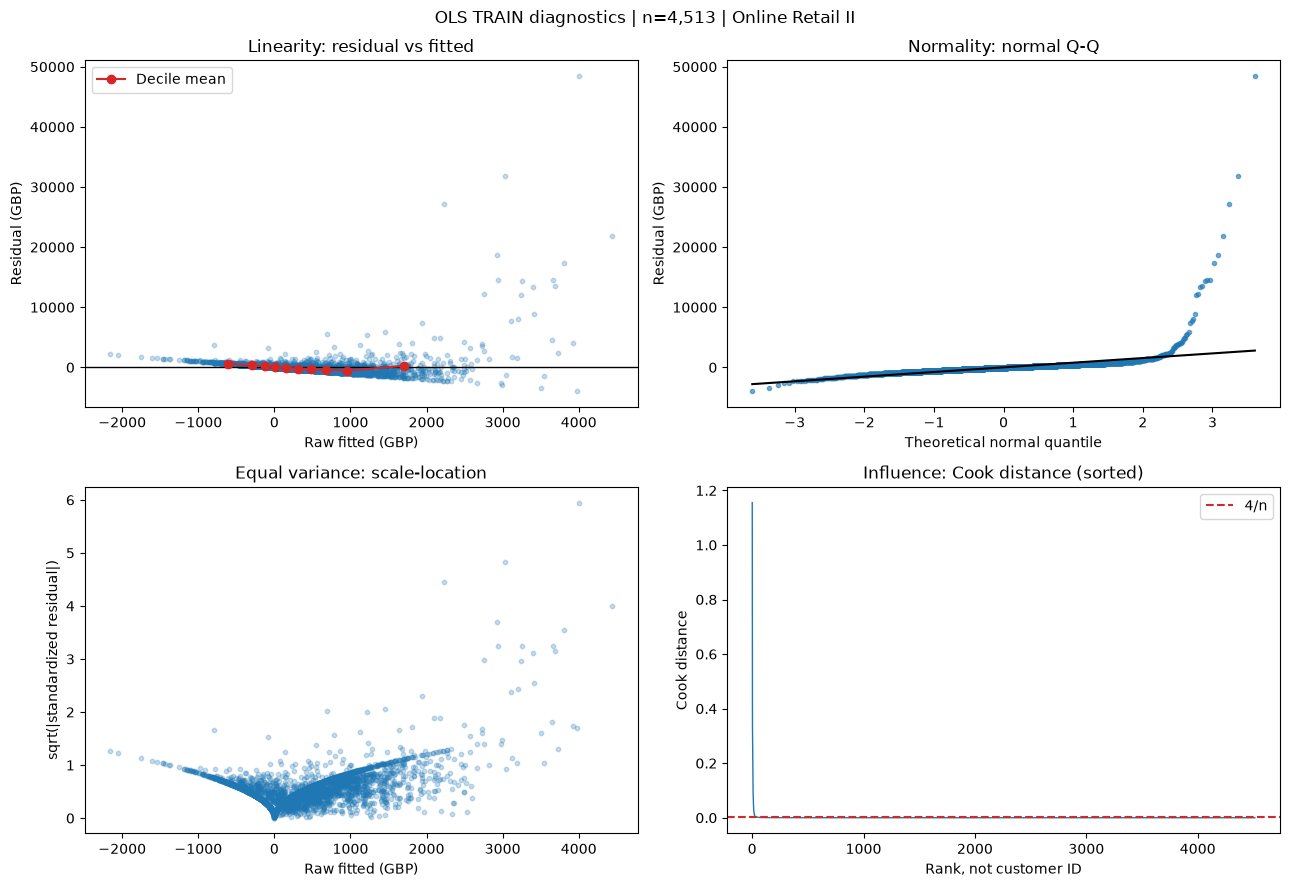

L: đọc đường trung bình theo decile; độ lệch khỏi zero gợi ý sai dạng hàm.
L: biên độ trung bình residual theo decile: [-541.00, +639.05] GBP; đối chiếu train MAE 496.85 GBP.
N / Jarque–Bera: p=0, có dấu hiệu vi phạm; chỉ là kiểm tra bổ trợ với giả định độc lập, đọc cùng đồ thị.
E / Koenker–Breusch–Pagan: p=7.17e-31, có dấu hiệu vi phạm; chỉ là kiểm tra bổ trợ với giả định độc lập, đọc cùng đồ thị.
N: QQ plot và độ lệch residual = 17.876; không kết luận chuẩn chỉ từ trung bình zero.
E: Spearman(|residual|, fitted) = 0.318; đọc cùng đồ thị scale-location, không phải kiểm định chính thức.
I: không xác minh độc lập giữa khách; so sánh residual giữa train và validation ở phần sau.
Giữ toàn bộ quan sát; không xóa khách vì Cook/VIF.


In [3]:
coef, vif, points, diagnostic = ols_diagnostics(models['OLS'], X_train, y_train)
display(pd.Series(diagnostic).to_frame('train_OLS'))
display(vif.sort_values('vif', ascending=False).round(4))
display(coef.round(4))
coef.to_csv(REPORTS/'regression_ols_coefficients.csv', index=False)
vif.to_csv(REPORTS/'regression_ols_vif.csv', index=False)
pd.DataFrame([diagnostic]).to_csv(REPORTS/'regression_ols_diagnostics.csv', index=False)
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
fitted = points.fitted_gbp.to_numpy(); residual = points.residual_gbp.to_numpy()
axes[0,0].scatter(fitted, residual, alpha=.25, s=10)
axes[0,0].axhline(0, color='black', lw=1)
# Binned means reveal systematic curvature even with heavy-tailed residuals.
if np.ptp(fitted)>0:
    bins = pd.qcut(fitted, q=10, duplicates='drop')
    means = points.groupby(bins, observed=True)[['fitted_gbp','residual_gbp']].mean()
    axes[0,0].plot(means.fitted_gbp, means.residual_gbp, 'o-', color='tab:red', label='Decile mean')
    axes[0,0].legend()
axes[0,0].set(title='Linearity: residual vs fitted', xlabel='Raw fitted (GBP)', ylabel='Residual (GBP)')
(theory, ordered), (slope, intercept, _) = stats.probplot(residual, dist='norm')
axes[0,1].scatter(theory, ordered, s=9, alpha=.6)
axes[0,1].plot(theory, intercept+slope*theory, color='black')
axes[0,1].set(title='Normality: normal Q-Q', xlabel='Theoretical normal quantile', ylabel='Residual (GBP)')
axes[1,0].scatter(fitted, np.sqrt(np.abs(points.standardized_residual)), alpha=.25, s=10)
axes[1,0].set(title='Equal variance: scale-location', xlabel='Raw fitted (GBP)', ylabel='sqrt(|standardized residual|)')
cook = np.sort(points.cooks_distance.dropna().to_numpy())[::-1]
axes[1,1].plot(np.arange(1,len(cook)+1), cook, lw=1)
axes[1,1].axhline(4/len(y_train), color='tab:red', ls='--', label='4/n')
axes[1,1].set(title='Influence: Cook distance (sorted)', xlabel='Rank, not customer ID', ylabel='Cook distance')
axes[1,1].legend()
fig.suptitle(f'OLS TRAIN diagnostics | n={len(y_train):,} | Online Retail II')
fig.tight_layout(); fig.savefig(FIGURES/'07_regression_ols_diagnostics.png', dpi=160, bbox_inches='tight'); plt.show()
print('L: đọc đường trung bình theo decile; độ lệch khỏi zero gợi ý sai dạng hàm.')
if np.ptp(fitted)>0:
    print(f'L: biên độ trung bình residual theo decile: [{means.residual_gbp.min():+.2f}, {means.residual_gbp.max():+.2f}] GBP; đối chiếu train MAE {np.mean(np.abs(residual)):.2f} GBP.')
for key, label in [('jarque_bera_p','N / Jarque–Bera'), ('koenker_bp_p','E / Koenker–Breusch–Pagan')]:
    p_value = diagnostic[key]
    status = ('có dấu hiệu vi phạm' if p_value < .05 else 'chưa đủ bằng chứng vi phạm') if np.isfinite(p_value) else 'không đủ điều kiện'
    print(f'{label}: p={p_value:.3g}, {status}; chỉ là kiểm tra bổ trợ với giả định độc lập, đọc cùng đồ thị.')
print(f'N: QQ plot và độ lệch residual = {diagnostic["residual_skew"]:.3f}; không kết luận chuẩn chỉ từ trung bình zero.')
print(f'E: Spearman(|residual|, fitted) = {diagnostic["spearman_abs_residual_fitted"]:.3f}; đọc cùng đồ thị scale-location, không phải kiểm định chính thức.')
print('I: không xác minh độc lập giữa khách; so sánh residual giữa train và validation ở phần sau.')
if diagnostic['rank_deficient']:
    print('Thiếu hạng: hệ số OLS không định danh duy nhất; không công bố CI riêng.')
elif not diagnostic['hc3_intervals_available']:
    print('Không đủ điều kiện tính HC3; CI để NaN.')
print('Giữ toàn bộ quan sát; không xóa khách vì Cook/VIF.')

## 3. Validation tháng 6 (chỉ kiểm tra tính ổn định)
Không đổi alpha, feature hay winner sau validation. Tương quan residual lặp lại của cùng khách giữa train và validation là chỉ báo mô tả phụ thuộc theo thời gian, không phải kiểm định độc lập giữa khách; train residual là in-sample. Chỉ xuất tổng hợp, không xuất Customer ID.

In [4]:
X_val, y_val = split_xy(snapshots['validation'])
validation = evaluate_models(models, X_val, y_val)
display(validation.round(4)); validation.to_csv(REPORTS/'regression_validation.csv')
train_err = pd.Series(y_train-models['OLS'].predict(X_train), index=snapshots['train'].customer_id, name='train')
val_err = pd.Series(y_val-models['OLS'].predict(X_val), index=snapshots['validation'].customer_id, name='validation')
paired = pd.concat([train_err, val_err], axis=1, join='inner').dropna()
rho = paired.corr(method='spearman').iloc[0,1] if len(paired)>=2 else np.nan
print(f'Khách lặp train/validation: {len(paired):,}; Spearman residual = {rho:.3f} (mô tả, không chứng minh I).')
print('Winner vẫn là:', winner)

,n,mae_gbp,rmse_gbp,r2,negative_raw_fraction,mean_error_gbp
model,,,,,,
Dummy median,4909,338.1545,2086.5166,-0.0270,0.0000,338.1545
OLS,4909,417.3034,1886.0020,0.1609,0.3573,-93.5230
Dummy mean,4909,484.1507,2058.9661,-0.0000,0.0000,11.7559
Ridge alpha=1000,4909,403.3769,1933.5892,0.1180,0.2609,-52.3151
Lasso alpha=100,4909,406.4567,1942.5477,0.1099,0.2275,-45.1672


Khách lặp train/validation: 4,513; Spearman residual = 0.678 (mô tả, không chứng minh I).
Winner vẫn là: Dummy median


## 4. Temporal test tháng 9
Bảng so sánh các mô hình đã khóa. Không thay winner nếu test cho kết quả khác CV. R² âm nghĩa là kém hơn dự báo trung bình của test theo định nghĩa R²; NaN nếu target hằng. Các metric trên GBP gốc, gồm cả giá trị 0 và khách chi tiêu lớn. Mean error dương là dự báo thiếu trung bình.

,n,mae_gbp,rmse_gbp,r2,negative_raw_fraction,mean_error_gbp
model,,,,,,
Dummy median,5225,515.3416,3144.9414,-0.0276,0.0000,515.3416
OLS,5225,495.9144,2922.4550,0.1127,0.3656,75.5007
Dummy mean,5225,597.4218,3108.1793,-0.0037,0.0000,188.9430
Ridge alpha=1000,5225,484.8469,2979.0627,0.0779,0.2779,123.2702
Lasso alpha=100,5225,493.8482,2986.9589,0.0731,0.2323,118.7443


Winner (locked): Dummy median
Test share zero: 0.5721
MAE gain vs median dummy (GBP): 0.0
RMSE gain vs mean dummy (GBP): -36.76


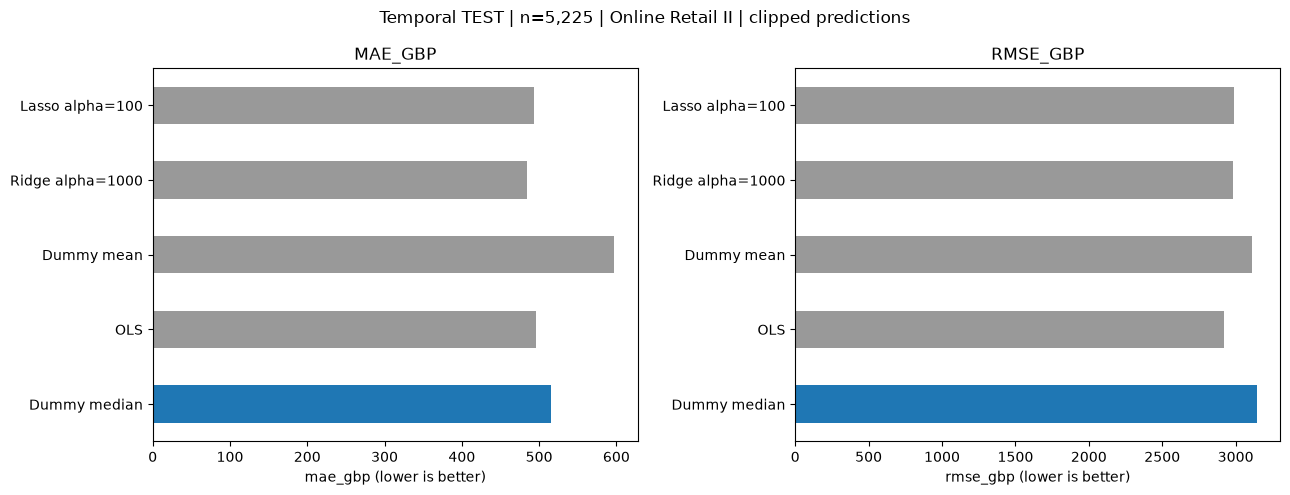

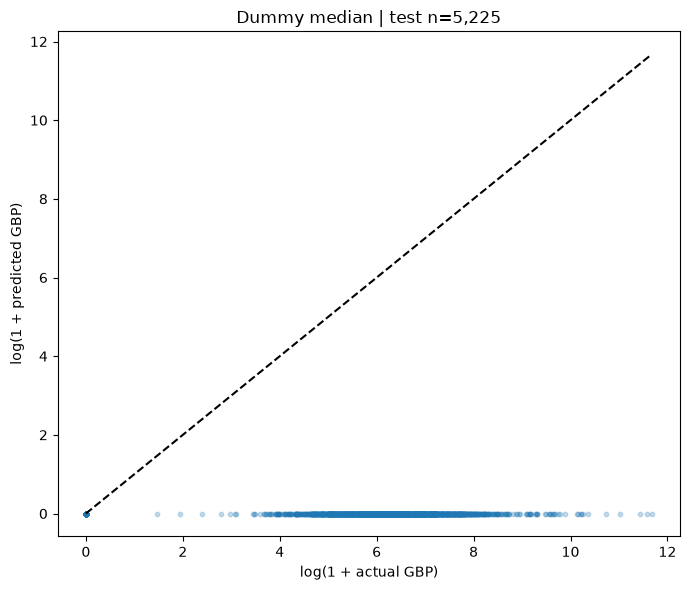

In [5]:
X_test, y_test = split_xy(snapshots['test'])
test = evaluate_models(models, X_test, y_test)
display(test.round(4)); test.to_csv(REPORTS/'regression_test.csv')
print('Winner (locked):', winner)
print('Test share zero:', round(np.mean(y_test==0),4))
pred = predict_gbp(models[winner], X_test)
print('MAE gain vs median dummy (GBP):', round(test.loc['Dummy median','mae_gbp']-test.loc[winner,'mae_gbp'],2))
print('RMSE gain vs mean dummy (GBP):', round(test.loc['Dummy mean','rmse_gbp']-test.loc[winner,'rmse_gbp'],2))
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for metric, ax in zip(['mae_gbp','rmse_gbp'], axes):
    test[metric].plot.barh(ax=ax, color=['tab:blue' if name==winner else '0.6' for name in test.index])
    ax.set(xlabel=f'{metric} (lower is better)', ylabel='', title=metric.upper())
fig.suptitle(f'Temporal TEST | n={len(y_test):,} | Online Retail II | clipped predictions')
fig.tight_layout(); fig.savefig(FIGURES/'08_regression_evaluation.png', dpi=160, bbox_inches='tight'); plt.show()
fig, ax=plt.subplots(figsize=(7,6))
ax.scatter(np.log1p(y_test), np.log1p(pred), s=10, alpha=.25)
end=max(np.log1p(y_test).max(),np.log1p(pred).max())
ax.plot([0,end],[0,end], color='black', ls='--')
ax.set(xlabel='log(1 + actual GBP)',ylabel='log(1 + predicted GBP)',title=f'{winner} | test n={len(y_test):,}')
fig.tight_layout(); fig.savefig(FIGURES/'09_regression_actual_vs_predicted.png', dpi=160, bbox_inches='tight'); plt.show()

## 5. Diễn giải và giới hạn
Các hệ số bên dưới của OLS mô tả quan hệ có điều kiện trong train, không phải nhân quả. Với log-feature, tăng một đơn vị biến đã scale tương ứng tăng `scale_` của log(1+x), các biến khác giữ nguyên; với feature tuyến tính, tăng một `scale_` trên thang gốc. Intercept tại tất cả transformed feature = 0, không phải khách không có lịch sử. HC3 95% CI là xấp xỉ dựa trên giả định độc lập; khi thiếu hạng thì không diễn giải hệ số riêng. Không dùng CI OLS cho Ridge/Lasso hoặc khoảng dự báo cá nhân. VIF cao/LINE vi phạm hạn chế kết luận; regularization giúp ổn định nhưng không tự chứng minh quan hệ nhân quả. Target gross không phải lợi nhuận. Các đơn lớn hiếm, zero nhiều, sai số có thể rất lớn; test hồi cứu, không phải dữ liệu mới năm 2026. Nên dùng dự báo tổng hợp để tham khảo phân khúc, không quyết định đối xử từng khách.

In [6]:
prep = models['OLS'].named_steps['prep']
scales = dict(zip(REG_FEATURES['log_num_cols'], prep.named_transformers_['log_num'].named_steps['scaler'].scale_))
scales.update(zip(REG_FEATURES['linear_num_cols'], prep.named_transformers_['linear_num'].named_steps['scaler'].scale_))
for row in coef.itertuples(index=False):
    name = row.feature.split('__')[-1]
    if diagnostic['rank_deficient']:
        print(f'{name}: không định danh duy nhất; không diễn giải riêng.'); continue
    unit = 'tại transformed features = 0' if name=='Intercept' else f'tăng {scales[name]:.4g} đơn vị '+('log(1+x)' if name in REG_FEATURES['log_num_cols'] else 'thang gốc')
    interval = f'95% HC3 CI [{row.ci95_low:+.2f}, {row.ci95_high:+.2f}]' if np.isfinite(row.hc3_se) else 'CI không đủ điều kiện'
    print(f'{name}: {unit}, hệ số {row.coefficient_gbp:+.2f} GBP ({interval}); giữ biến khác cố định.')
if winner not in ('OLS','Dummy median','Dummy mean'):
    reg = models[winner].named_steps['reg']
    display(pd.DataFrame({'feature': models[winner].named_steps['prep'].get_feature_names_out(), 'penalized_coefficient_gbp': reg.coef_}))
    print('Hệ số penalized: mô tả mô hình dự báo, bị shrinkage; không gán CI OLS.')
print(f'Kết luận dự báo: {winner}, test MAE £{test.loc[winner,"mae_gbp"]:,.2f}, RMSE £{test.loc[winner,"rmse_gbp"]:,.2f}, R² {test.loc[winner,"r2"]:.4f}.')
if test.loc[winner,'mae_gbp'] >= test.loc['Dummy median','mae_gbp']:
    print('Không cải thiện MAE so với median baseline trên test; chưa đủ cơ sở khuyến nghị sử dụng dự báo phức tạp.')
else:
    print('Cải thiện MAE so với median baseline trên test hồi cứu; cân nhắc RMSE và các lỗi ở nhóm chi tiêu cao trước khi áp dụng.')

Intercept: tại transformed features = 0, hệ số -60.36 GBP (95% HC3 CI [-146.42, +25.70]); giữ biến khác cố định.
recency_days: tăng 1.336 đơn vị log(1+x), hệ số +68.35 GBP (95% HC3 CI [-34.14, +170.84]); giữ biến khác cố định.
observation_span_days: tăng 0.8871 đơn vị log(1+x), hệ số -227.85 GBP (95% HC3 CI [-337.32, -118.38]); giữ biến khác cố định.
frequency: tăng 1.099 đơn vị log(1+x), hệ số +1177.67 GBP (95% HC3 CI [+814.07, +1541.28]); giữ biến khác cố định.
avg_order_value: tăng 0.8598 đơn vị log(1+x), hệ số +462.73 GBP (95% HC3 CI [+281.61, +643.85]); giữ biến khác cố định.
unique_products: tăng 1.552 đơn vị log(1+x), hệ số -378.35 GBP (95% HC3 CI [-529.53, -227.17]); giữ biến khác cố định.
peak_month_ratio: tăng 0.3697 đơn vị thang gốc, hệ số -23.21 GBP (95% HC3 CI [-47.09, +0.67]); giữ biến khác cố định.
cancel_rate: tăng 0.1715 đơn vị thang gốc, hệ số -84.42 GBP (95% HC3 CI [-137.50, -31.35]); giữ biến khác cố định.
Kết luận dự báo: Dummy median, test MAE £515.34, RMSE £3,144